# Fundamentos da Programação de Redes Neurais
### Da Notação Matemática à Implementação Vetorizada — Notebook Interativo

Este notebook acompanha o texto teórico e demonstra, em código, cada um dos
conceitos apresentados: notação, o neurônio único (regressão logística),
funções de perda e custo, a fundamentação por Máxima Verossimilhança, o
grafo de computação, o gradiente descendente, a vetorização e o
*broadcasting*. A última seção reúne tudo em uma implementação de ponta a
ponta, treinada em um *dataset* sintético.

Cada seção segue o mesmo padrão: **explicação em Markdown → demonstração em
código**.

## 0. Setup

Importamos apenas `numpy` (álgebra linear), `matplotlib` (visualização) e
`time` (para os benchmarks da Seção 7). Nenhuma outra dependência externa é
necessária — toda a implementação, incluindo a geração de dados sintéticos
da Seção 10, usa **NumPy puro**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Semente fixa para reprodutibilidade dos exemplos aleatórios do notebook
np.random.seed(42)

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Setup ok — NumPy", np.__version__)

Setup ok — NumPy 1.26.4


## 1. Notação e Estruturas

A convenção padrão empilha cada exemplo de treinamento $x^{(i)}$ como uma
**coluna** da matriz $X$, de dimensão $n_x \times m$:

$$X = \begin{bmatrix} \vert & \vert & & \vert \\ x^{(1)} & x^{(2)} & \cdots & x^{(m)} \\ \vert & \vert & & \vert \end{bmatrix} \in \mathbb{R}^{n_x \times m}$$

Abaixo, criamos um $X$ de brinquedo com $n_x = 3$ características e $m = 5$
exemplos, e um vetor de rótulos $Y$ de shape $(1, m)$, apenas para tornar a
notação concreta antes de usá-la nas seções seguintes.

In [2]:
n_x, m = 3, 5  # 3 caracteristicas, 5 exemplos

X_toy = np.random.randn(n_x, m)
Y_toy = np.random.randint(0, 2, size=(1, m))

print("Shape de X (n_x, m):", X_toy.shape)
print("Shape de Y (1, m)  :", Y_toy.shape)
print()
print("X =\n", np.round(X_toy, 2))
print()
print("Y =", Y_toy)
print()
print("Exemplo (coluna) i=0 -> x^(0) =", X_toy[:, 0])

Shape de X (n_x, m): (3, 5)
Shape de Y (1, m)  : (1, 5)

X =
 [[ 0.5  -0.14  0.65  1.52 -0.23]
 [-0.23  1.58  0.77 -0.47  0.54]
 [-0.46 -0.47  0.24 -1.91 -1.72]]

Y = [[0 0 1 1 1]]

Exemplo (coluna) i=0 -> x^(0) = [ 0.49671415 -0.23413696 -0.46341769]


## 2. Classificação Binária e o Neurônio Único

A Regressão Logística — o "neurônio elementar" — calcula, em duas etapas:

$$z = w^Tx + b \qquad\qquad \hat{y} = a = \sigma(z) = \frac{1}{1+e^{-z}}$$

Implementamos a função Sigmoide e visualizamos seu comportamento: ela
comprime qualquer valor real no intervalo $(0,1)$, permitindo interpretar a
saída como uma probabilidade.

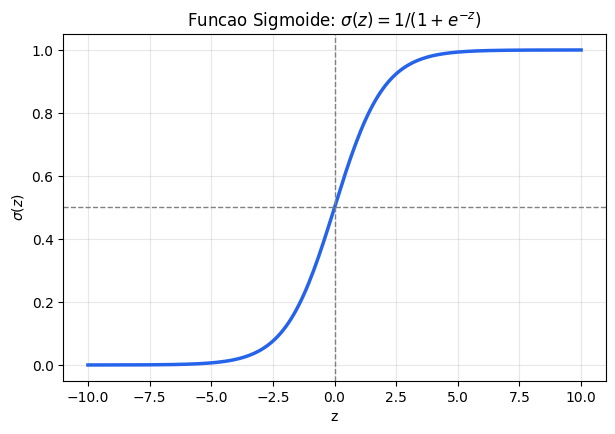

In [3]:
def sigmoid(z):
    """Calcula a funcao sigmoide de z (aceita escalar, vetor ou matriz)."""
    return 1 / (1 + np.exp(-z))

# Visualizando a curva sigmoide
z_vals = np.linspace(-10, 10, 200)
plt.plot(z_vals, sigmoid(z_vals), linewidth=2.5, color="#2563eb")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.title(r"Funcao Sigmoide: $\sigma(z) = 1/(1+e^{-z})$")
plt.xlabel("z")
plt.ylabel(r"$\sigma(z)$")
plt.show()

In [4]:
# Predicao para um unico exemplo (neuronio unico)
w = np.array([[0.5], [-0.2], [0.1]])  # shape (n_x, 1)
b = 0.1

x_exemplo = X_toy[:, 0:1]  # shape (n_x, 1) - mantendo 2D, nunca (n_x,)

z = np.dot(w.T, x_exemplo) + b
a = sigmoid(z)

print("z =", round(z.item(), 4))
print("a = sigmoid(z) =", round(a.item(), 4), " -> P(y=1|x)")

z = 0.3488
a = sigmoid(z) = 0.5863  -> P(y=1|x)


## 3. Funções de Erro: Perda (Loss) vs. Custo (Cost)

$$\mathcal{L}(\hat y, y) = -\big(y\log\hat y + (1-y)\log(1-\hat y)\big) \qquad\qquad J(w,b) = \frac{1}{m}\sum_{i=1}^{m}\mathcal{L}(\hat y^{(i)}, y^{(i)})$$

Implementamos as duas funções e recriamos o gráfico que mostra o
comportamento **exponencial** da perda: quanto mais confiante e errada a
predição, maior a penalidade.

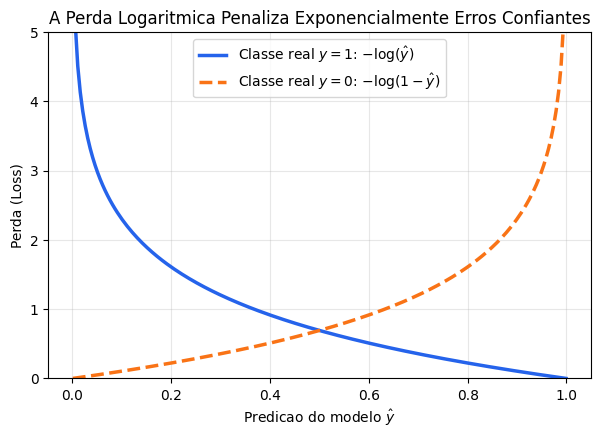

In [5]:
def loss(y_hat, y, eps=1e-12):
    """Perda logaritmica para um unico exemplo (ou vetorizada)."""
    y_hat = np.clip(y_hat, eps, 1 - eps)  # evita log(0)
    return -(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def cost(Y_hat, Y):
    """Funcao de custo: media das perdas sobre m exemplos."""
    m = Y.shape[1]
    return (1 / m) * np.sum(loss(Y_hat, Y))

# Reproduzindo o grafico da perda logaritmica
y_hat_range = np.linspace(0.001, 0.999, 200)

plt.plot(y_hat_range, loss(y_hat_range, 1), label=r"Classe real $y=1$: $-\log(\hat y)$",
         color="#2563eb", linewidth=2.5)
plt.plot(y_hat_range, loss(y_hat_range, 0), label=r"Classe real $y=0$: $-\log(1-\hat y)$",
         color="#f97316", linewidth=2.5, linestyle="--")
plt.title("A Perda Logaritmica Penaliza Exponencialmente Erros Confiantes")
plt.xlabel(r"Predicao do modelo $\hat y$")
plt.ylabel("Perda (Loss)")
plt.ylim(0, 5)
plt.legend()
plt.show()

In [6]:
# Custo medio sobre os 5 exemplos de brinquedo (Secao 1), com predicoes aleatorias
A_toy = sigmoid(np.random.randn(1, m))  # predicoes ficticias, shape (1, m)
J = cost(A_toy, Y_toy)

print("Predicoes (A):", np.round(A_toy, 3))
print("Rotulos   (Y):", Y_toy)
print("Custo J(w,b) =", round(J, 4))

Predicoes (A): [[0.363 0.555 0.317 0.536 0.491]]
Rotulos   (Y): [[0 0 1 1 1]]
Custo J(w,b) = 0.7491


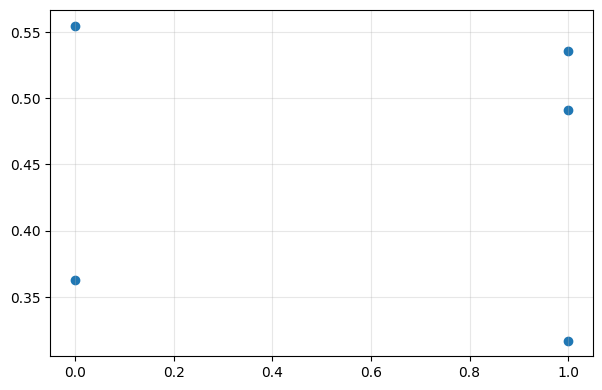

In [7]:
plt.scatter(Y_toy,np.round(A_toy, 3));

## 4. Fundamentação Estatística: Máxima Verossimilhança

Minimizar $J(w,b)$ é matematicamente equivalente a **maximizar** a
log-verossimilhança dos dados sob a premissa i.i.d.:

$$\log P(\text{dados}\mid w,b) = \sum_{i=1}^m\Big[y^{(i)}\log\hat y^{(i)} + (1-y^{(i)})\log(1-\hat y^{(i)})\Big] = -m \cdot J(w,b)$$

Verificamos essa equivalência numericamente: para um pequeno conjunto de
predições e rótulos, calculamos $J$ e a log-verossimilhança e confirmamos
que $\text{log-verossimilhança} = -m \cdot J$.

In [8]:
def log_likelihood(Y_hat, Y, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return np.sum(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

J = cost(A_toy, Y_toy)
ll = log_likelihood(A_toy, Y_toy)

print("Custo J(w,b)            =", round(J, 6))
print("Log-verossimilhanca     =", round(ll, 6))
print("-m * J                  =", round(-m * J, 6))
print()
print("Equivalencia confirmada:", np.isclose(ll, -m * J))

Custo J(w,b)            = 0.749108
Log-verossimilhanca     = -3.745542
-m * J                  = -3.745542

Equivalencia confirmada: True


## 5. Grafo de Computação e *Backpropagation*

**Forward pass:** $x,w,b \to z=w^Tx+b \to a=\sigma(z) \to \mathcal{L}(a,y)$

**Backward pass** (regra da cadeia), para 1 exemplo:

$$dz = a - y \qquad\qquad dw = x\cdot dz \qquad\qquad db = dz$$

Implementamos o forward e o backward manualmente para um único exemplo e
validamos o gradiente analítico contra uma aproximação por **diferenças
finitas** (*gradient checking*) — uma prática padrão para detectar erros na
derivação de gradientes.

In [9]:
def forward_backward_1_exemplo(w, b, x, y):
    """Forward + backward manual para 1 unico exemplo. x: (n_x, 1)."""
    # Forward
    z = np.dot(w.T, x) + b
    a = sigmoid(z)
    L = loss(a, y)

    # Backward (regra da cadeia)
    dz = a - y
    dw = x * dz          # shape (n_x, 1)
    db = dz               # escalar (1,1)

    return L.item(), dw, db.item()

# Gradient checking: comparar dw analitico com aproximacao numerica
def gradient_checking(w, b, x, y, epsilon=1e-7):
    L, dw_analitico, db_analitico = forward_backward_1_exemplo(w, b, x, y)

    dw_numerico = np.zeros_like(w)
    for i in range(w.shape[0]):
        w_mais = w.copy(); w_mais[i, 0] += epsilon
        w_menos = w.copy(); w_menos[i, 0] -= epsilon
        L_mais, _, _ = forward_backward_1_exemplo(w_mais, b, x, y)
        L_menos, _, _ = forward_backward_1_exemplo(w_menos, b, x, y)
        dw_numerico[i, 0] = (L_mais - L_menos) / (2 * epsilon)

    erro_relativo = np.linalg.norm(dw_analitico - dw_numerico) / (
        np.linalg.norm(dw_analitico) + np.linalg.norm(dw_numerico) + 1e-12
    )
    return dw_analitico, dw_numerico, erro_relativo

x_teste = X_toy[:, 0:1]
y_teste = Y_toy[0, 0]

dw_a, dw_n, erro = gradient_checking(w, b, x_teste, y_teste)

print("dw analitico :", dw_a.ravel())
print("dw numerico  :", dw_n.ravel())
print("Erro relativo:", erro, " (esperado: << 1e-5)")

dw analitico : [ 0.29124184 -0.13728314 -0.2717189 ]
dw numerico  : [ 0.29124184 -0.13728314 -0.2717189 ]
Erro relativo: 8.683564962834833e-10  (esperado: << 1e-5)


## 6. Gradiente Descendente

Regra de atualização: $w := w - \alpha\, dw \qquad b := b - \alpha\, db$

Aplicamos o gradiente descendente (ainda não-vetorizado, exemplo a exemplo)
a um pequeno conjunto de dados de brinquedo linearmente separável, e
observamos o custo $J$ cair a cada época.

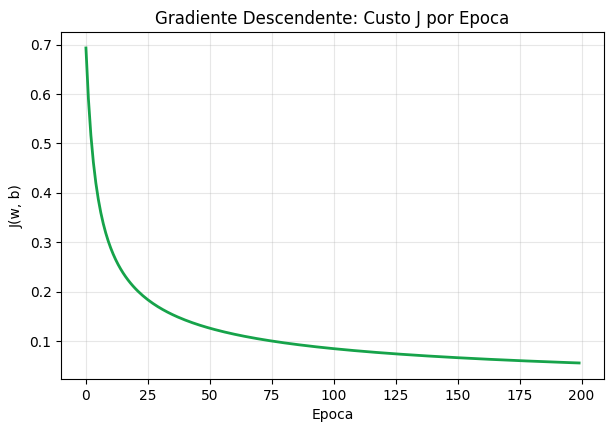

Custo inicial: 0.6931  ->  Custo final: 0.0559


In [10]:
# Dataset de brinquedo linearmente separavel (2 features, 20 exemplos)
m_small = 20
X_small = np.random.randn(2, m_small)
# Rotulo: y=1 se a soma das features for positiva (fronteira linear simples)
Y_small = (X_small[0, :] + X_small[1, :] > 0).astype(float).reshape(1, m_small)

w_gd = np.zeros((2, 1))
b_gd = 0.0
alpha = 0.5
epocas = 200
custos_gd = []

for epoca in range(epocas):
    dw_acumulado = np.zeros((2, 1))
    db_acumulado = 0.0
    custo_epoca = 0.0

    # Loop for explicito sobre os exemplos (nao vetorizado - ver Secao 7)
    for i in range(m_small):
        xi = X_small[:, i:i+1]
        yi = Y_small[0, i]
        Li, dwi, dbi = forward_backward_1_exemplo(w_gd, b_gd, xi, yi)
        dw_acumulado += dwi
        db_acumulado += dbi
        custo_epoca += Li

    dw_acumulado /= m_small
    db_acumulado /= m_small
    custo_epoca /= m_small
    custos_gd.append(custo_epoca)

    w_gd -= alpha * dw_acumulado
    b_gd -= alpha * db_acumulado

plt.plot(custos_gd, color="#16a34a", linewidth=2)
plt.title("Gradiente Descendente: Custo J por Epoca")
plt.xlabel("Epoca")
plt.ylabel("J(w, b)")
plt.show()

print(f"Custo inicial: {custos_gd[0]:.4f}  ->  Custo final: {custos_gd[-1]:.4f}")

## 7. Vetorização

Forward e backward vetorizados para todo o conjunto de exemplos de uma vez:

$$Z = w^TX + b \qquad A = \sigma(Z) \qquad dZ = A - Y \qquad dw = \frac{1}{m}X\,dZ^T \qquad db = \frac{1}{m}\sum dZ$$

Comparamos a versão com loop `for` explícito (Seção 6) contra a versão
vetorizada, medindo o tempo de execução de uma única época de cálculo do
gradiente.

> **Parâmetros configuráveis:** ajuste `M_BENCHMARK` (número de exemplos) e
> `N_FEATURES_BENCHMARK` (número de características) na célula abaixo para
> reproduzir o benchmark em qualquer escala — inclusive a escala maior usada
> no texto original (50.000 × 100), que aqui é reduzida por padrão para que
> o notebook rode rapidamente.

In [11]:
# --------------------------------------------------------------------
# CONFIGURACAO DO BENCHMARK - ajuste livremente
# --------------------------------------------------------------------
M_BENCHMARK = 5_000            # numero de exemplos de treinamento
N_FEATURES_BENCHMARK = 50      # numero de caracteristicas (features)
# --------------------------------------------------------------------

X_bench = np.random.randn(N_FEATURES_BENCHMARK, M_BENCHMARK)
Y_bench = np.random.randint(0, 2, size=(1, M_BENCHMARK)).astype(float)
w_bench = np.random.randn(N_FEATURES_BENCHMARK, 1) * 0.01
b_bench = 0.0

print(f"Benchmark configurado para m={M_BENCHMARK:,} exemplos, "
      f"n_x={N_FEATURES_BENCHMARK} caracteristicas "
      f"({M_BENCHMARK * N_FEATURES_BENCHMARK:,} pontos de dados)")

Benchmark configurado para m=5,000 exemplos, n_x=50 caracteristicas (250,000 pontos de dados)


In [12]:
def gradiente_com_loop(X, Y, w, b):
    """Calcula dw, db iterando exemplo a exemplo (abordagem ineficiente)."""
    n_x, m = X.shape
    dw = np.zeros((n_x, 1))
    db = 0.0
    for i in range(m):
        xi = X[:, i:i+1]
        zi = np.dot(w.T, xi) + b
        ai = sigmoid(zi)
        dzi = ai - Y[0, i]
        dw += (xi * dzi)
        db += dzi.item()
    return dw / m, db / m

def gradiente_vetorizado(X, Y, w, b):
    """Calcula dw, db com operacoes matriciais (sem loops)."""
    m = X.shape[1]
    Z = np.dot(w.T, X) + b
    A = sigmoid(Z)
    dZ = A - Y
    dw = (1 / m) * np.dot(X, dZ.T)
    db = (1 / m) * np.sum(dZ)
    return dw, db


def medir_tempo_ms(func, *args, duracao_alvo_s=0.05):
    """
    Mede o tempo medio de execucao de func (em ms), repetindo a chamada
    automaticamente ate acumular pelo menos `duracao_alvo_s` segundos.
    Isso evita medicoes de 0 ms quando M_BENCHMARK/N_FEATURES_BENCHMARK
    sao pequenos e a funcao roda mais rapido que a resolucao do relogio.
    """
    # Chamada unica para calibrar quantas repeticoes sao necessarias
    inicio = time.perf_counter()
    resultado = func(*args)
    tempo_uma_chamada = time.perf_counter() - inicio

    if tempo_uma_chamada <= 0:
        repeticoes = 1000  # funcao extremamente rapida: usa um piso alto
    else:
        repeticoes = max(1, int(duracao_alvo_s / tempo_uma_chamada))

    inicio = time.perf_counter()
    for _ in range(repeticoes):
        resultado = func(*args)
    tempo_total_ms = (time.perf_counter() - inicio) * 1000

    return tempo_total_ms / repeticoes, resultado


# Medindo o tempo de cada abordagem (media sobre repeticoes calibradas)
tempo_loop, (dw_loop, db_loop) = medir_tempo_ms(gradiente_com_loop, X_bench, Y_bench, w_bench, b_bench)
tempo_vet, (dw_vet, db_vet) = medir_tempo_ms(gradiente_vetorizado, X_bench, Y_bench, w_bench, b_bench)

# Verificando que os dois metodos produzem o mesmo resultado
print("Resultados equivalentes (dw):", np.allclose(dw_loop, dw_vet, atol=1e-8))
print("Resultados equivalentes (db):", np.isclose(db_loop, db_vet, atol=1e-8))
print()
print(f"Loop for tradicional : {tempo_loop:10.4f} ms")
print(f"Abordagem vetorizada : {tempo_vet:10.4f} ms")

if tempo_vet > 0:
    print(f"Aceleracao            : {tempo_loop / tempo_vet:10.1f}x")
else:
    print("Aceleracao            : nao mensuravel (tempo vetorizado abaixo da resolucao do relogio)")

Resultados equivalentes (dw): True
Resultados equivalentes (db): True

Loop for tradicional :    86.0075 ms
Abordagem vetorizada :     0.5082 ms
Aceleracao            :      169.2x


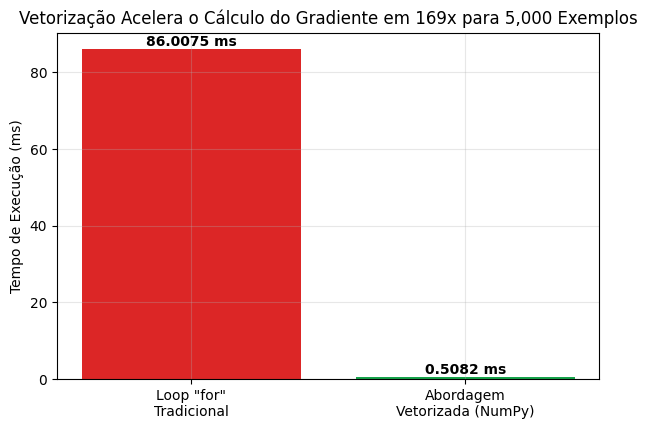

In [13]:
# Grafico comparativo (mesmo estilo do benchmark do texto original)
metodos = ['Loop "for"\nTradicional', "Abordagem\nVetorizada (NumPy)"]
tempos = [tempo_loop, tempo_vet]

titulo_aceleracao = f"{tempo_loop / tempo_vet:.0f}x" if tempo_vet > 0 else "N/D"

plt.bar(metodos, tempos, color=["#dc2626", "#16a34a"])
for i, t in enumerate(tempos):
    plt.text(i, t, f"{t:.4f} ms", ha="center", va="bottom", fontweight="bold")
plt.ylabel("Tempo de Execução (ms)")
plt.title(f"Vetorização Acelera o Cálculo do Gradiente em {titulo_aceleracao} "
          f"para {M_BENCHMARK:,} Exemplos")
plt.show()

## 8. Broadcasting e Robustez na Implementação

*Rank-1 arrays* (shape `(n,)`) são uma fonte comum de bugs silenciosos de
*broadcasting*. Demonstramos o problema e como um `assert` de shape o
detecta imediatamente.

In [14]:
# O BUG: um array de rank 1
vetor_perigoso = np.random.randn(5)
print("Shape de um rank-1 array:", vetor_perigoso.shape, "<- ambiguo! Nao eh (5,1) nem (1,5)")

# Multiplicar um rank-1 array por seu "transposto" NAO gera um produto externo,
# como se esperaria de um vetor coluna x vetor linha:
resultado_errado = np.dot(vetor_perigoso, vetor_perigoso.T)
print("np.dot(v, v.T) com rank-1 array produz um ESCALAR:", resultado_errado, "(inesperado!)")
print()

# A CORRECAO: forcar shape bidimensional explicito
vetor_seguro = np.random.randn(5, 1)  # vetor coluna explicito
resultado_correto = np.dot(vetor_seguro, vetor_seguro.T)
print("Shape correto (5,1):", vetor_seguro.shape)
print("np.dot(v, v.T) agora produz uma matriz (5,5):", resultado_correto.shape)

Shape de um rank-1 array: (5,) <- ambiguo! Nao eh (5,1) nem (1,5)
np.dot(v, v.T) com rank-1 array produz um ESCALAR: 1.7013655822777376 (inesperado!)

Shape correto (5,1): (5, 1)
np.dot(v, v.T) agora produz uma matriz (5,5): (5, 5)


In [15]:
# Usando assert para proteger o pipeline contra esse bug
def somar_pesos_segura(w):
    assert w.shape == (5, 1), f"Shape inesperado: {w.shape}. Use .reshape(-1, 1)."
    return w.sum()

try:
    somar_pesos_segura(vetor_perigoso)  # vai falhar - shape (5,) nao passa no assert
except AssertionError as e:
    print("AssertionError capturado como esperado:", e)

# Reshape defensivo corrige o problema
vetor_corrigido = vetor_perigoso.reshape(-1, 1)
print()
print("Apos reshape defensivo, shape =", vetor_corrigido.shape)
print("Soma:", somar_pesos_segura(vetor_corrigido))

AssertionError capturado como esperado: Shape inesperado: (5,). Use .reshape(-1, 1).

Apos reshape defensivo, shape = (5, 1)
Soma: 0.5805061499598738


## 9. Guia de Referência Rápida

| Etapa | Exemplo único $(i)$ | Vetorizado ($m$ exemplos) | Código NumPy |
|---|---|---|---|
| Entrada | $x^{(i)} \in \mathbb{R}^{n_x}$ | $X \in \mathbb{R}^{n_x \times m}$ | `X` shape `(n_x, m)` |
| Combinação linear | $z^{(i)} = w^Tx^{(i)}+b$ | $Z = w^TX + b$ | `Z = np.dot(w.T, X) + b` |
| Ativação | $a^{(i)} = \sigma(z^{(i)})$ | $A = \sigma(Z)$ | `A = 1/(1+np.exp(-Z))` |
| Custo | $\mathcal{L}(a^{(i)}, y^{(i)})$ | $J = \frac1m\sum \mathcal{L}$ | `-1/m*np.sum(Y*np.log(A)+...)` |
| Grad. ativação | $dz^{(i)} = a^{(i)}-y^{(i)}$ | $dZ = A-Y$ | `dZ = A - Y` |
| Grad. pesos | $dw^{(i)} = x^{(i)}dz^{(i)}$ | $dw = \frac1m X dZ^T$ | `dw = 1/m*np.dot(X, dZ.T)` |
| Grad. viés | $db^{(i)} = dz^{(i)}$ | $db = \frac1m\sum dz^{(i)}$ | `db = 1/m*np.sum(dZ)` |

Esta tabela resume tudo o que foi implementado nas Seções 2 a 7. A seguir,
reunimos essas peças em uma implementação de ponta a ponta.

## 10. Implementação Completa: Treinamento de Ponta a Ponta

Reunimos tudo em quatro funções — `sigmoid`, `inicializar_parametros`,
`otimizar` e `prever` — e treinamos em um *dataset* sintético 2D gerado com
**NumPy puro** (duas nuvens gaussianas), o que nos permite visualizar a
**fronteira de decisão** aprendida pelo modelo.

> **Geração de dados configurável:** `gerar_dataset_gaussiano` aceita
> `n_por_classe`, `separacao` e `seed` como parâmetros — ajuste livremente
> para gerar datasets mais fáceis/difíceis de separar.

In [16]:
def gerar_dataset_gaussiano(n_por_classe=100, separacao=2.5, seed=1):
    """
    Gera um dataset sintetico 2D com duas classes (nuvens gaussianas),
    usando apenas NumPy. Parametros configuraveis:
      - n_por_classe: numero de exemplos por classe
      - separacao: distancia entre os centros das duas nuvens (maior = mais facil)
      - seed: semente para reprodutibilidade
    Retorna X (2, m) e Y (1, m), no formato vetorizado padrao do curso.
    """
    rng = np.random.RandomState(seed)

    centro_0 = np.array([-separacao / 2, -separacao / 2])
    centro_1 = np.array([separacao / 2, separacao / 2])

    classe_0 = rng.randn(n_por_classe, 2) + centro_0
    classe_1 = rng.randn(n_por_classe, 2) + centro_1

    X = np.vstack([classe_0, classe_1]).T          # shape (2, m)
    Y = np.hstack([np.zeros(n_por_classe), np.ones(n_por_classe)]).reshape(1, -1)

    # Embaralhar as colunas para misturar as classes
    perm = rng.permutation(X.shape[1])
    return X[:, perm], Y[:, perm]


def inicializar_parametros(dimensao):
    """Inicializa w como vetor coluna de zeros e b como escalar zero."""
    w = np.zeros((dimensao, 1))
    b = 0.0
    assert w.shape == (dimensao, 1)
    return w, b


def otimizar(X, Y, num_iteracoes=1000, learning_rate=0.1, verbose=True):
    """Executa o Gradiente Descendente vetorizado para treinar w e b."""
    n_x, m = X.shape
    w, b = inicializar_parametros(n_x)
    custos = []

    for i in range(num_iteracoes):
        # 1. Forward Propagation (vetorizado)
        Z = np.dot(w.T, X) + b
        A = sigmoid(Z)

        # 2. Custo
        custo = -1 / m * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))
        custos.append(custo)

        # 3. Backward Propagation (vetorizado)
        dZ = A - Y
        dw = 1 / m * np.dot(X, dZ.T)
        db = 1 / m * np.sum(dZ)

        assert dw.shape == w.shape
        assert isinstance(db, float) or np.isscalar(db)

        # 4. Atualizacao
        w = w - learning_rate * dw
        b = b - learning_rate * db

        if verbose and i % 200 == 0:
            print(f"Custo apos a iteracao {i}: {custo:.6f}")

    return w, b, custos


def prever(w, b, X):
    """Gera previsoes binarias (0 ou 1) para um conjunto de entradas X."""
    A = sigmoid(np.dot(w.T, X) + b)
    return (A > 0.5).astype(float)

In [26]:
# --------------------------------------------------------------------
# CONFIGURACAO DO DATASET E DO TREINAMENTO - ajuste livremente
# --------------------------------------------------------------------
N_POR_CLASSE = 150
SEPARACAO = 2.5
SEED_DADOS = 1
NUM_ITERACOES = 1000
LEARNING_RATE = 0.5
# --------------------------------------------------------------------

X_full, Y_full = gerar_dataset_gaussiano(
    n_por_classe=N_POR_CLASSE, separacao=SEPARACAO, seed=SEED_DADOS
)

print("Shape de X:", X_full.shape, " | Shape de Y:", Y_full.shape)

w_final, b_final, custos_final = otimizar(
    X_full, Y_full, num_iteracoes=NUM_ITERACOES, learning_rate=LEARNING_RATE
)

previsoes = prever(w_final, b_final, X_full)
acuracia = np.mean(previsoes == Y_full) * 100
print(f"\nAcuracia final no conjunto de treino: {acuracia:.2f}%")

Shape de X: (2, 300)  | Shape de Y: (1, 300)
Custo apos a iteracao 0: 0.693147
Custo apos a iteracao 200: 0.118269
Custo apos a iteracao 400: 0.118180
Custo apos a iteracao 600: 0.118179
Custo apos a iteracao 800: 0.118179

Acuracia final no conjunto de treino: 96.00%


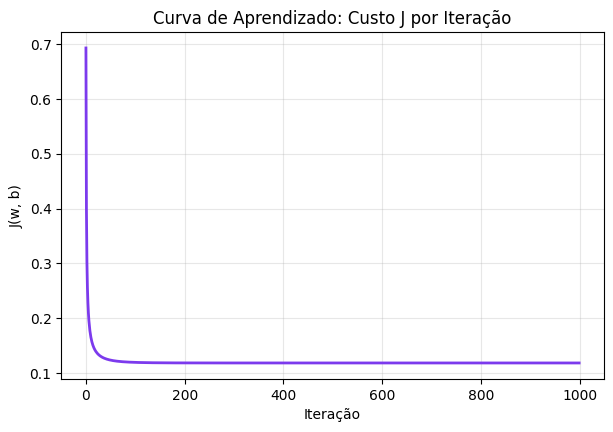

In [27]:
# Curva de aprendizado
plt.plot(custos_final, color="#7c3aed", linewidth=2)
plt.title("Curva de Aprendizado: Custo J por Iteração")
plt.xlabel("Iteração")
plt.ylabel("J(w, b)")
plt.show()

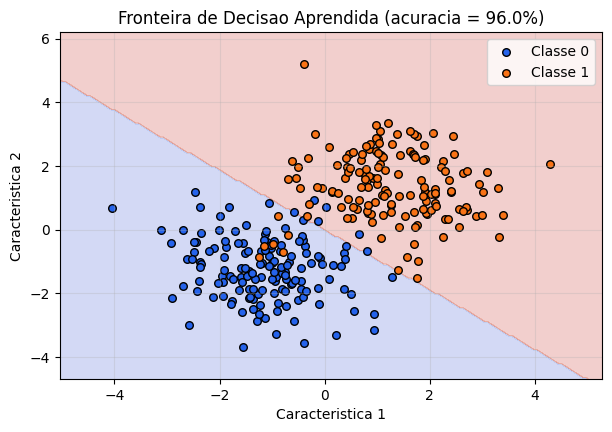

In [28]:
# Visualizando a fronteira de decisao aprendida
def plotar_fronteira_decisao(X, Y, w, b, resolucao=200):
    x_min, x_max = X[0, :].min() - 1, X[0, :].max() + 1
    y_min, y_max = X[1, :].min() - 1, X[1, :].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolucao),
                          np.linspace(y_min, y_max, resolucao))

    grade = np.vstack([xx.ravel(), yy.ravel()])  # shape (2, resolucao*resolucao)
    Z = prever(w, b, grade).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(X[0, Y[0] == 0], X[1, Y[0] == 0], label="Classe 0",
                color="#2563eb", edgecolor="k", s=30)
    plt.scatter(X[0, Y[0] == 1], X[1, Y[0] == 1], label="Classe 1",
                color="#f97316", edgecolor="k", s=30)
    plt.xlabel("Caracteristica 1")
    plt.ylabel("Caracteristica 2")
    plt.title(f"Fronteira de Decisao Aprendida (acuracia = {acuracia:.1f}%)")
    plt.legend()
    plt.show()

plotar_fronteira_decisao(X_full, Y_full, w_final, b_final)

## 11. Conclusão

Neste notebook, cada conceito teórico foi acompanhado de uma demonstração em
código:

- **Notação e estruturas** → shapes concretos de $X$ e $Y$
- **Neurônio único** → `sigmoid()` e uma predição de exemplo
- **Perda e custo** → `loss()`, `cost()` e o gráfico da penalidade exponencial
- **Máxima Verossimilhança** → equivalência numérica $J = -\frac{1}{m}\,\text{log-verossimilhança}$
- **Grafo de computação** → forward/backward manual validado por *gradient checking*
- **Gradiente descendente** → curva de custo caindo a cada época
- **Vetorização** → benchmark configurável loop vs. matricial
- **Broadcasting** → o bug do rank-1 array e sua correção
- **Implementação completa** → treinamento de ponta a ponta com fronteira de decisão visualizada

A partir daqui, o próximo passo natural é estender essa mesma estrutura
— parametrização, forward/backward, custo convexo, vetorização — para
**múltiplas camadas**, o que transforma a Regressão Logística em uma
Rede Neural Profunda propriamente dita.